# 05 · Outliers de episodios y dataset final

Analiza valores extremos e inconsistencias a nivel de episodio en el dataset preliminar del notebook 03, aplica las reglas de episodio decididas por el equipo (`REGLAS_EPISODIO` en `src/config.py`) y exporta el dataset final.

In [1]:
import json
import sys
from datetime import datetime
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, estilo
from src.estilo import fmt_decimal, fmt_entero, fmt_pct
from src.graficos import (
    COLORES_GRUPO,
    ETIQUETAS_CORTAS_GRUPO,
    activar_formato_tablas,
    aplicar_estilo,
    envolver_etiqueta,
    guardar_figura,
    linea_umbral,
    rotular_barras,
    titulo_hallazgo,
)
from src.limpieza import (
    aplicar_reglas_episodio,
    conteo_por_paciente_anio,
    detectar_episodios,
    resumen_marcas,
)
from src.privacidad import enmascarar_pequenos, suprimir_pequenos, tabla_segura
from src.tablas import mostrar_tabla, tabla_medidas

aplicar_estilo()
activar_formato_tablas()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

G1, G2, G3 = config.GRUPOS
VERDE = estilo.VERDE
NOMBRE_CRITERIO = {'p99': 'percentil 99', 'p99_9': 'percentil 99,9'}


def columnas_caso(clave):
    """Columnas de marca de un caso: una, o una por criterio."""
    return [c for c in marcas.columns if c == clave or c.startswith(f'{clave}__')]


def etiqueta_columna(columna):
    clave, _, criterio = columna.partition('__')
    nombre = config.REGLAS_EPISODIO[clave]['descripcion']
    return f'{nombre} ({NOMBRE_CRITERIO.get(criterio, criterio)})' if criterio else nombre


def mostrar_afectados(clave):
    """Episodios afectados (n y %) por columna de marca, en total y por grupo."""
    columnas = columnas_caso(clave)
    mostrar_tabla(tabla_segura(resumen_marcas(marcas[columnas])),
                  f"{config.REGLAS_EPISODIO[clave]['descripcion']}: episodios afectados")
    por_grupo = marcas[columnas].groupby(poblacion['grupo']).sum().astype('int64')
    por_grupo = por_grupo.reindex(list(config.GRUPOS), fill_value=0).add_prefix('n_')
    por_grupo.insert(0, 'n', poblacion['grupo'].value_counts().reindex(list(config.GRUPOS), fill_value=0))
    mostrar_tabla(tabla_segura(por_grupo.rename_axis('grupo'), conservar_ceros=True),
                  f"{config.REGLAS_EPISODIO[clave]['descripcion']}: episodios afectados por grupo")


def grafico_por_grupo(clave, nombre_figura):
    """% de episodios de cada grupo afectados por un caso."""
    marca = marcas[clave]
    tabla = pd.DataFrame({'n': poblacion['grupo'].value_counts(), 'n_afectados': marca.groupby(poblacion['grupo']).sum()})
    tabla = tabla.reindex(list(config.GRUPOS), fill_value=0).astype('int64')
    tabla['pct_afectados'] = 100 * tabla['n_afectados'] / tabla['n']
    valores = tabla['pct_afectados'].where(tabla['n_afectados'] >= config.MIN_CELDA)
    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(tabla))
    barras = ax.bar(x, valores, color=[COLORES_GRUPO[g] for g in tabla.index], width=0.6)
    rotular_barras(ax, barras, valores, formato=fmt_pct)
    ax.set_xticks(x, [ETIQUETAS_CORTAS_GRUPO[g] for g in tabla.index])
    ax.set_ylabel('% de episodios del grupo')
    titulo_hallazgo(fig, f"{config.REGLAS_EPISODIO[clave]['descripcion']} por grupo",
                    '% de episodios de cada grupo afectados; grupos con menos de 10 episodios afectados sin barra')
    guardar_figura(fig, nombre_figura)
    plt.show()


def grafico_conteos(conteos, limite, titulo, subtitulo, nombre_figura, etiqueta_x):
    """Tabla y barras de frecuencias agregadas, en escala log, con el límite de detección."""
    conteos = conteos.sort_index()
    mostrar_tabla(suprimir_pequenos(conteos.rename('n').to_frame(), ['n']), titulo)
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.bar(conteos.index, enmascarar_pequenos(conteos, conteos), width=0.8, color=VERDE)
    ax.set_yscale('log')
    if limite is not None and not np.isnan(limite):
        linea_umbral(ax, limite, f'Percentil 99,9: {fmt_decimal(limite, 1)}', destacada=False)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel('Frecuencia (escala log)')
    titulo_hallazgo(fig, titulo, subtitulo)
    guardar_figura(fig, nombre_figura)
    plt.show()

## 1. Datos

Dataset preliminar de episodios del notebook 03, población de análisis (`en_poblacion == True`).

In [2]:
nombre_preliminar = f'episodios_preliminar_{config.UMBRAL_FUSION_MIN}min'
ruta_episodios = config.DATA_INTERIM / f'{nombre_preliminar}.parquet'
if not ruta_episodios.exists():
    tabla_medidas({'archivo': f'data/interim/{ruta_episodios.name}', 'aviso': 'El archivo no existe.',
                   'qué hacer': 'Corre el notebook 03 para crear el dataset preliminar.'}, 'Dataset no disponible')
    raise SystemExit('Dataset no disponible: la celda se detiene.')

episodios = pd.read_parquet(ruta_episodios)
with open(config.DATA_INTERIM / f'{nombre_preliminar}.json', encoding='utf-8') as archivo:
    metadatos_preliminar = json.load(archivo)
poblacion = episodios[episodios['en_poblacion']].copy()

## 2. Marcas y límites

Se calculan las marcas de cada caso y los límites de detección sobre la población de análisis.

In [3]:
marcas, limites_usados = detectar_episodios(poblacion)

## 3. LOS extremo
### Detección

Por grupo (atención en urgencias y hospitalizado): LOS por encima del percentil 99 y del percentil 99,9.

In [4]:
filas = []
for grupo in config.GRUPOS_TIEMPOS:
    los = poblacion.loc[poblacion['grupo'].eq(grupo), 'los_h'].dropna()
    filas.append({
        'grupo': ETIQUETAS_CORTAS_GRUPO[grupo],
        'n': len(los),
        'p99_h': los.quantile(0.99),
        'p99_9_h': los.quantile(0.999),
        'n_mas_720h': int(los.gt(720).sum()),
        'n_mas_1440h': int(los.gt(1440).sum()),
        'max_h': los.max(),
    })
maximos = pd.DataFrame(filas).set_index('grupo')
mostrar_tabla(tabla_segura(maximos, conservar_ceros=True), 'LOS por grupo: percentiles, episodios de más de 720 h y 1.440 h, y máximo')

**LOS por grupo: percentiles, episodios de más de 720 h y 1.440 h, y máximo**

,n,p99_h,p99_9_h,n_mas_720h,n_mas_1440h,max_h
grupo,,,,,,
Atención en urgencias,192.046,"150,36","364,85",15,<10,"5.625,85"
Hospitalizado,34.533,"206,87","609,35",21,<10,"3.661,22"


### Episodios afectados

Episodios marcados con cada criterio, lado a lado.

In [5]:
mostrar_afectados('los_extremo')

**LOS extremo: episodios afectados**

,n,n_afectados,pct_afectados
marca,,,
los_extremo__p99,442.598,2.267,"0,5"
los_extremo__p99_9,442.598,228,"0,1"


**LOS extremo: episodios afectados por grupo**

,n,n_los_extremo__p99,n_los_extremo__p99_9
grupo,,,
1_contacto_breve,216.019,0,0
2_atencion_urgencias,192.046,1.921,193
3_hospitalizado,34.533,346,35


### Distribución

LOS en tramos de 0,1 en escala log10, por grupo, con los percentiles 99 y 99,9.

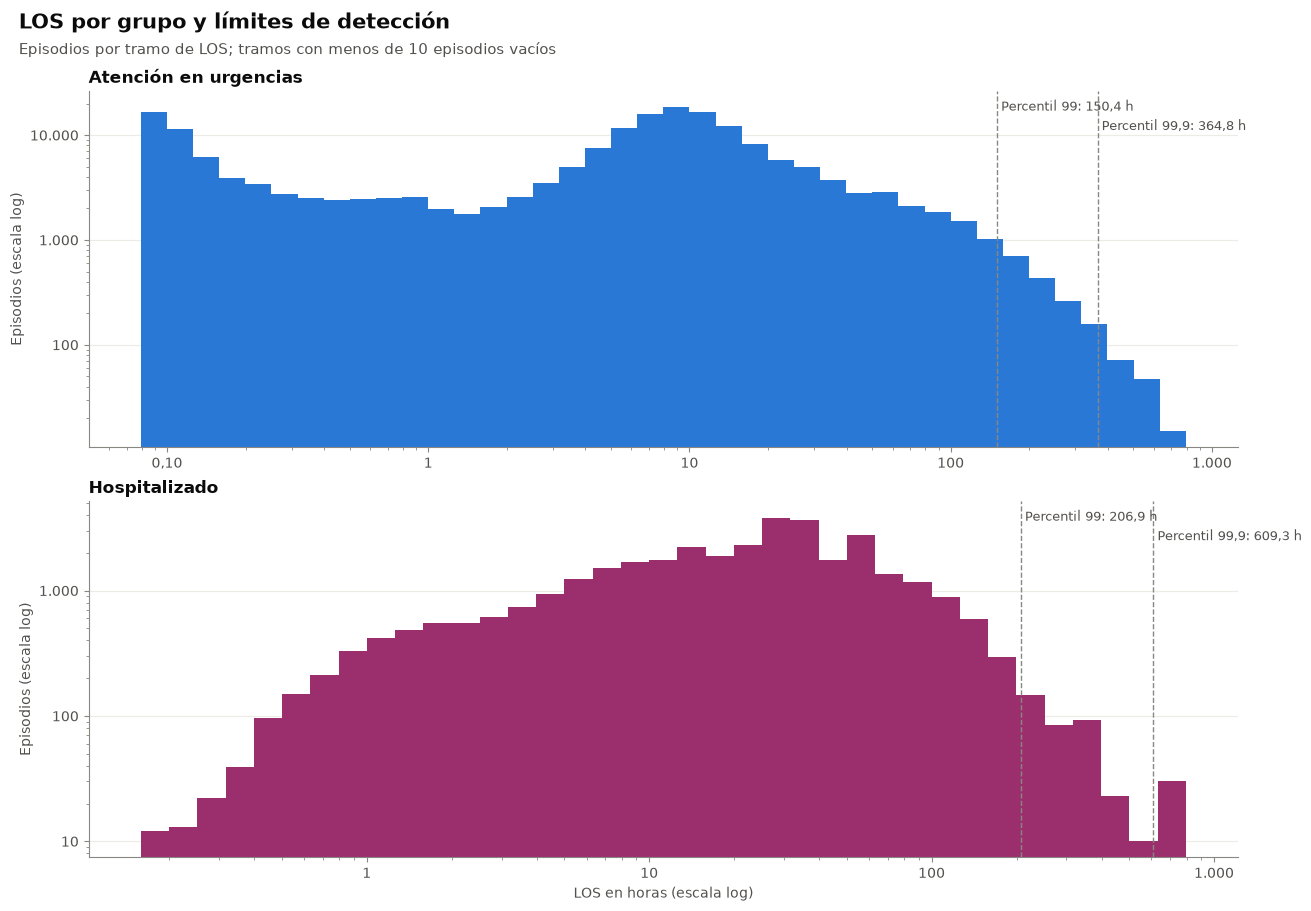

In [6]:
fig, ejes = plt.subplots(2, 1, figsize=(13, 9))
for ax, grupo in zip(ejes, config.GRUPOS_TIEMPOS):
    los = poblacion.loc[poblacion['grupo'].eq(grupo) & poblacion['los_h'].gt(0), 'los_h']
    if los.empty:
        continue
    bordes = 10 ** np.arange(np.floor(np.log10(los.min()) * 10) / 10, np.log10(los.max()) + 0.1, 0.1)
    conteos, _ = np.histogram(los, bins=bordes)
    conteos = np.where(conteos >= config.MIN_CELDA, conteos, np.nan)
    ax.bar(bordes[:-1], conteos, width=np.diff(bordes), align='edge', color=COLORES_GRUPO[grupo])
    ax.set_xscale('log')
    ax.set_yscale('log')
    for i, (criterio, limite) in enumerate(limites_usados['los_extremo'][grupo].items()):
        linea_umbral(ax, limite, f'{NOMBRE_CRITERIO[criterio].capitalize()}: {fmt_decimal(limite, 1)} h', destacada=False, fila=i)
    ax.set_ylabel('Episodios (escala log)')
    ax.set_title(ETIQUETAS_CORTAS_GRUPO[grupo])
ejes[1].set_xlabel('LOS en horas (escala log)')
titulo_hallazgo(fig, 'LOS por grupo y límites de detección', 'Episodios por tramo de LOS; tramos con menos de 10 episodios vacíos')
guardar_figura(fig, '05_los_extremo')
plt.show()

## 4. Fines con fracción de segundo
### Detección

Alguna visita del episodio tiene un fin de etapa con fracción de segundo (marca del notebook 03).

### Episodios afectados

In [7]:
mostrar_afectados('fin_fraccion_segundo')

**Fines con fracción de segundo: episodios afectados**

,n,n_afectados,pct_afectados
marca,,,
fin_fraccion_segundo,442.598,<10,suprimido


**Fines con fracción de segundo: episodios afectados por grupo**

,n,n_fin_fraccion_segundo
grupo,,
1_contacto_breve,216.019,0
2_atencion_urgencias,192.046,<10
3_hospitalizado,34.533,<10


### Distribución

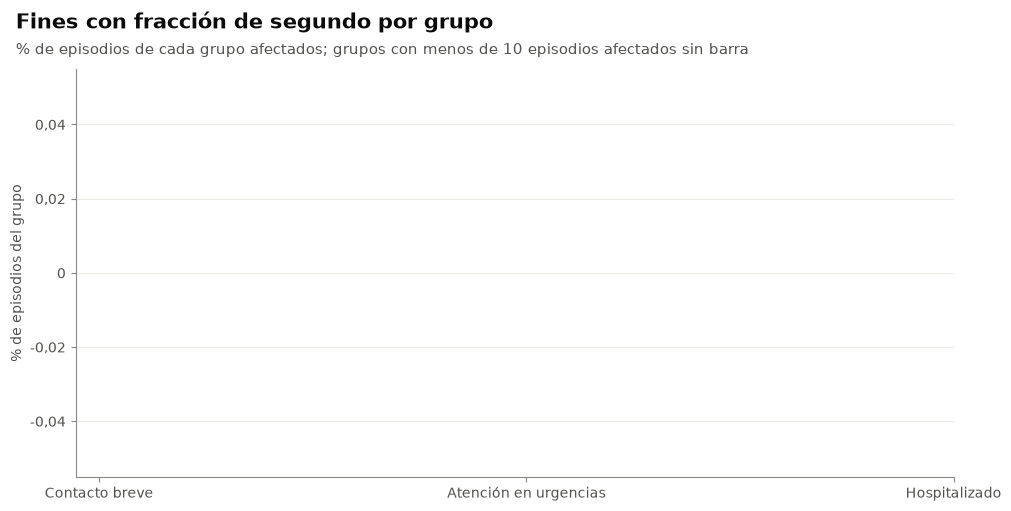

In [8]:
grafico_por_grupo('fin_fraccion_segundo', '05_fin_fraccion_segundo')

## 5. Muchas visitas unidas en un episodio
### Detección

`n_visitas` por encima del percentil 99,9.

### Episodios afectados

In [9]:
mostrar_afectados('muchas_visitas_en_episodio')

**Muchas visitas unidas en un episodio: episodios afectados**

,n,n_afectados,pct_afectados
marca,,,
muchas_visitas_en_episodio,442.598,32,"0,0"


**Muchas visitas unidas en un episodio: episodios afectados por grupo**

,n,n_muchas_visitas_en_episodio
grupo,,
1_contacto_breve,216.019,0
2_atencion_urgencias,192.046,19
3_hospitalizado,34.533,13


### Distribución

**Visitas por episodio**

,n
n_visitas,
1,343.203
2,97.340
3,1.351
4,672
5,<10
6,17
7,<10
8,<10
9,<10


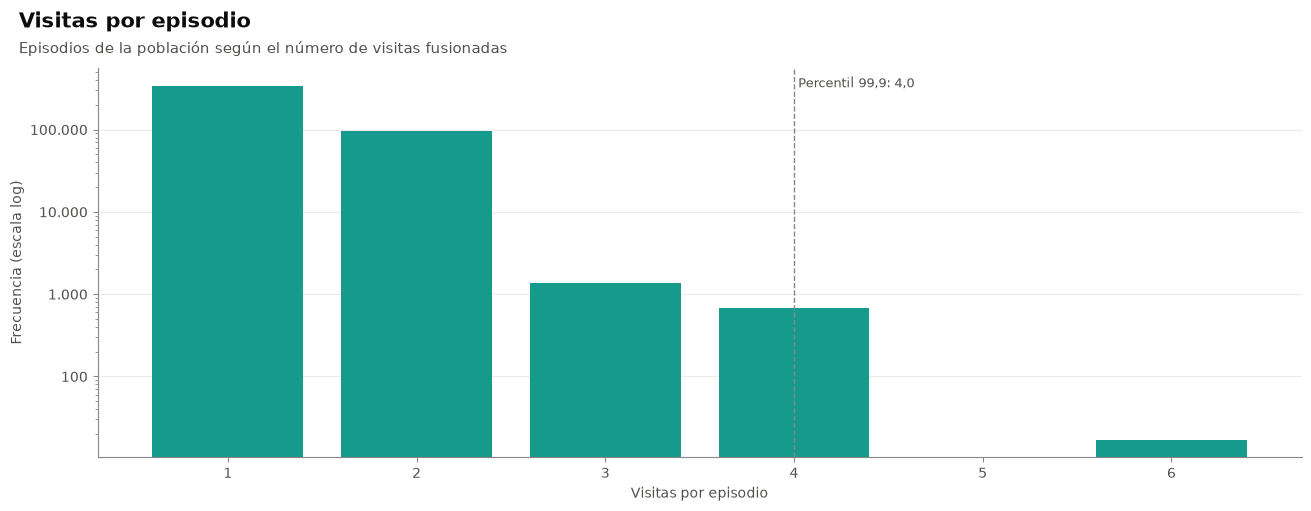

In [10]:
grafico_conteos(poblacion['n_visitas'].value_counts(), limites_usados['muchas_visitas_en_episodio'],
                'Visitas por episodio', 'Episodios de la población según el número de visitas fusionadas',
                '05_visitas_por_episodio', 'Visitas por episodio')

## 6. LOS recortado a 0
### Detección

Hospitalizado con `inicio_piso` anterior a la llegada (marca `los_recortado` de la construcción de episodios).

### Episodios afectados

In [11]:
mostrar_afectados('los_recortado')

**LOS recortado a 0: episodios afectados**

,n,n_afectados,pct_afectados
marca,,,
los_recortado,442.598,<10,suprimido


**LOS recortado a 0: episodios afectados por grupo**

,n,n_los_recortado
grupo,,
1_contacto_breve,216.019,0
2_atencion_urgencias,192.046,0
3_hospitalizado,34.533,0


### Distribución

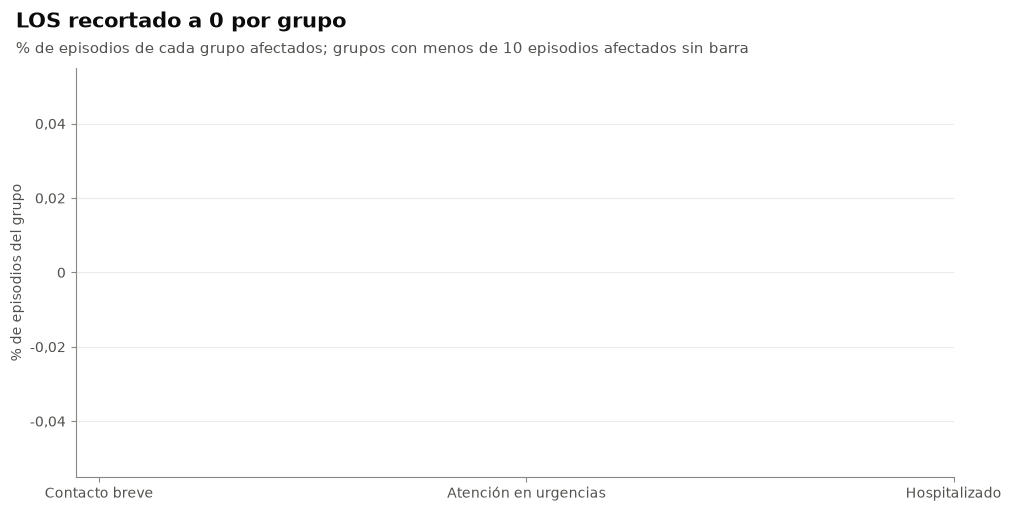

In [12]:
grafico_por_grupo('los_recortado', '05_los_recortado')

## 7. Hospitalizado con etapas de urgencias después de subir a piso
### Detección

Hospitalizado con `fin_urg > inicio_piso`.

### Episodios afectados

In [13]:
mostrar_afectados('hosp_etapas_urg_despues_de_piso')

**Hospitalizado con etapas de urgencias después de subir a piso: episodios afectados**

,n,n_afectados,pct_afectados
marca,,,
hosp_etapas_urg_despues_de_piso,442.598,1.329,"0,3"


**Hospitalizado con etapas de urgencias después de subir a piso: episodios afectados por grupo**

,n,n_hosp_etapas_urg_despues_de_piso
grupo,,
1_contacto_breve,216.019,0
2_atencion_urgencias,192.046,0
3_hospitalizado,34.533,1.329


### Distribución

Horas entre el inicio del piso y el fin de las etapas de urgencias, en los episodios afectados.

**Fin de las etapas de urgencias después del inicio del piso**

,n_episodios
horas después del inicio del piso,
hasta 1 h,133
1 a 4 h,205
4 a 12 h,283
12 a 24 h,186
1 a 3 d,295
3 a 7 d,140
más de 7 d,87


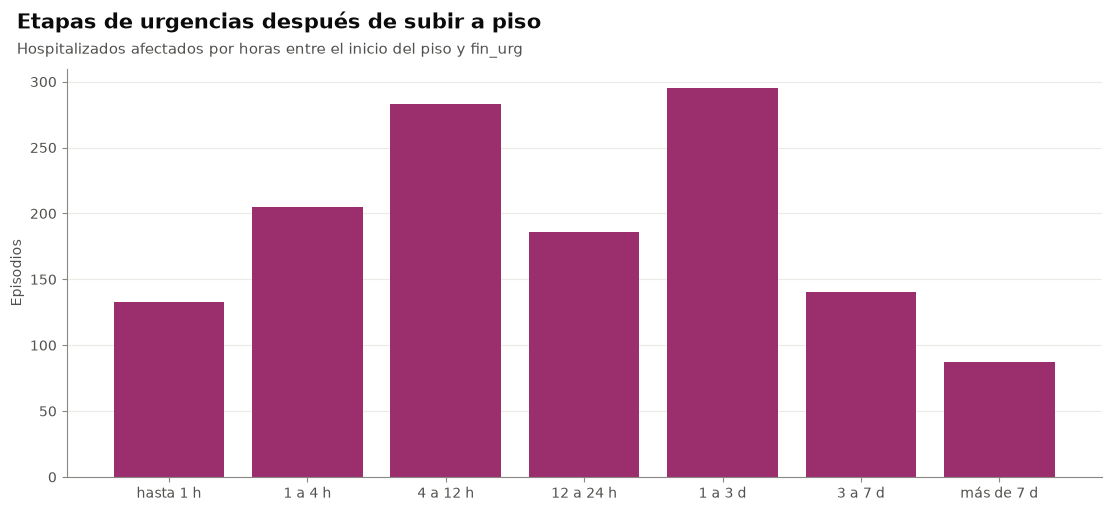

In [14]:
afectados = poblacion[marcas['hosp_etapas_urg_despues_de_piso']]
horas = (afectados['fin_urg'] - afectados['inicio_piso']).dt.total_seconds() / 3600
tramos = pd.cut(horas, bins=[0, 1, 4, 12, 24, 72, 168, np.inf], right=True,
                labels=['hasta 1 h', '1 a 4 h', '4 a 12 h', '12 a 24 h', '1 a 3 d', '3 a 7 d', 'más de 7 d'])
conteo = tramos.value_counts().sort_index()
mostrar_tabla(suprimir_pequenos(conteo.rename('n_episodios').rename_axis('horas después del inicio del piso').to_frame(),
                                ['n_episodios']), 'Fin de las etapas de urgencias después del inicio del piso')
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(range(len(conteo)), enmascarar_pequenos(conteo, conteo), color=COLORES_GRUPO[G3])
ax.set_xticks(range(len(conteo)), [str(c) for c in conteo.index])
ax.set_ylabel('Episodios')
titulo_hallazgo(fig, 'Etapas de urgencias después de subir a piso', 'Hospitalizados afectados por horas entre el inicio del piso y fin_urg')
guardar_figura(fig, '05_etapas_urg_despues_de_piso')
plt.show()

## 8. Contacto breve por visitas unidas
### Detección

Contacto breve con LOS ≥ 5 min: visitas sin etapas unidas en un mismo episodio, cuyo LOS va de la primera a la última llegada.

### Episodios afectados

In [15]:
mostrar_afectados('contacto_breve_por_visitas_unidas')

**Contacto breve por visitas unidas: episodios afectados**

,n,n_afectados,pct_afectados
marca,,,
contacto_breve_por_visitas_unidas,442.598,135,"0,0"


**Contacto breve por visitas unidas: episodios afectados por grupo**

,n,n_contacto_breve_por_visitas_unidas
grupo,,
1_contacto_breve,216.019,135
2_atencion_urgencias,192.046,0
3_hospitalizado,34.533,0


### Distribución

Visitas por episodio en los contactos breves afectados.

**Visitas por episodio en los contactos breves por visitas unidas**

,n
n_visitas,
2,131
3,<10
4,<10


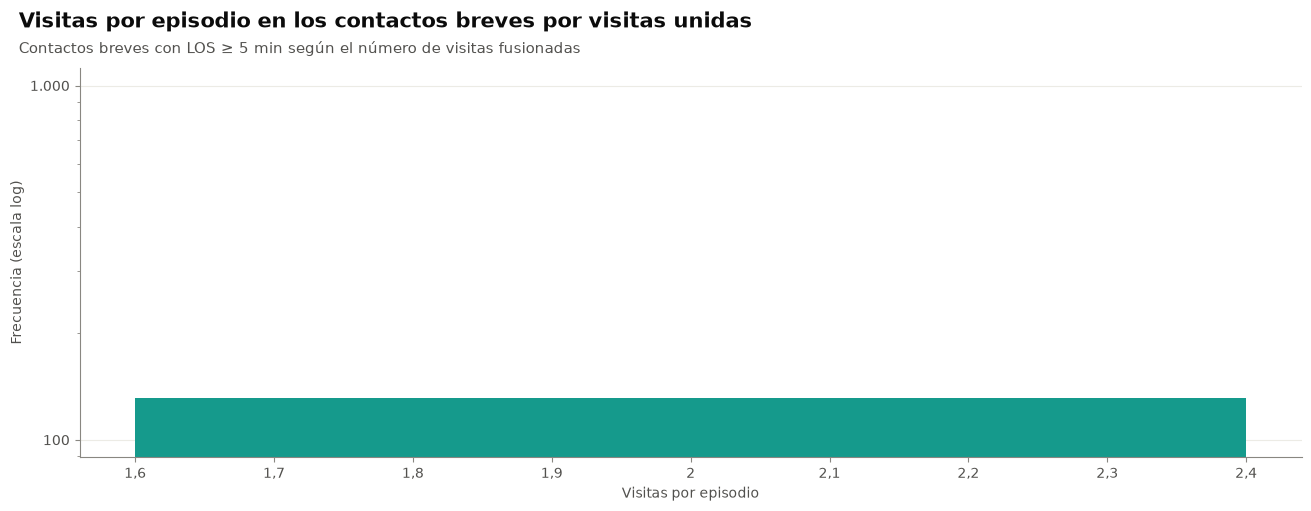

In [16]:
grafico_conteos(poblacion.loc[marcas['contacto_breve_por_visitas_unidas'], 'n_visitas'].value_counts(), None,
                'Visitas por episodio en los contactos breves por visitas unidas',
                'Contactos breves con LOS ≥ 5 min según el número de visitas fusionadas',
                '05_contacto_breve_por_visitas_unidas', 'Visitas por episodio')

## 9. Otras inconsistencias lógicas
### Detección

Hospitalizado sin `inicio_piso`; atención en urgencias con LOS < 5 min; `fin_urg < llegada`.

### Episodios afectados

In [17]:
for clave in ['hosp_sin_inicio_piso', 'atencion_menos_5min', 'fin_urg_antes_llegada']:
    mostrar_afectados(clave)

**Hospitalizado sin inicio de piso: episodios afectados**

,n,n_afectados,pct_afectados
marca,,,
hosp_sin_inicio_piso,442.598,<10,suprimido


**Hospitalizado sin inicio de piso: episodios afectados por grupo**

,n,n_hosp_sin_inicio_piso
grupo,,
1_contacto_breve,216.019,0
2_atencion_urgencias,192.046,0
3_hospitalizado,34.533,0


**Atención en urgencias con LOS < 5 min: episodios afectados**

,n,n_afectados,pct_afectados
marca,,,
atencion_menos_5min,442.598,<10,suprimido


... (2 outputs left out)

**Fin de urgencias antes de la llegada: episodios afectados**

,n,n_afectados,pct_afectados
marca,,,
fin_urg_antes_llegada,442.598,<10,suprimido


**Fin de urgencias antes de la llegada: episodios afectados por grupo**

,n,n_fin_urg_antes_llegada
grupo,,
1_contacto_breve,216.019,0
2_atencion_urgencias,192.046,0
3_hospitalizado,34.533,0


## 10. Pacientes con muchísimos episodios
### Detección

Episodios del mismo paciente en el mismo año por encima del percentil 99,9. Se marcan todos los episodios de ese paciente en ese año.

### Episodios afectados

In [18]:
mostrar_afectados('paciente_muchos_episodios')

**Pacientes con muchísimos episodios: episodios afectados**

,n,n_afectados,pct_afectados
marca,,,
paciente_muchos_episodios,442.598,423,"0,1"


**Pacientes con muchísimos episodios: episodios afectados por grupo**

,n,n_paciente_muchos_episodios
grupo,,
1_contacto_breve,216.019,255
2_atencion_urgencias,192.046,160
3_hospitalizado,34.533,<10


### Distribución

Pacientes-año según su número de episodios en el año.

**Episodios por paciente y año**

,n
llegada,
1,208.841
2,53.611
3,18.035
4,7.317
5,3.176
6,1.549
7,798
8,419
9,242


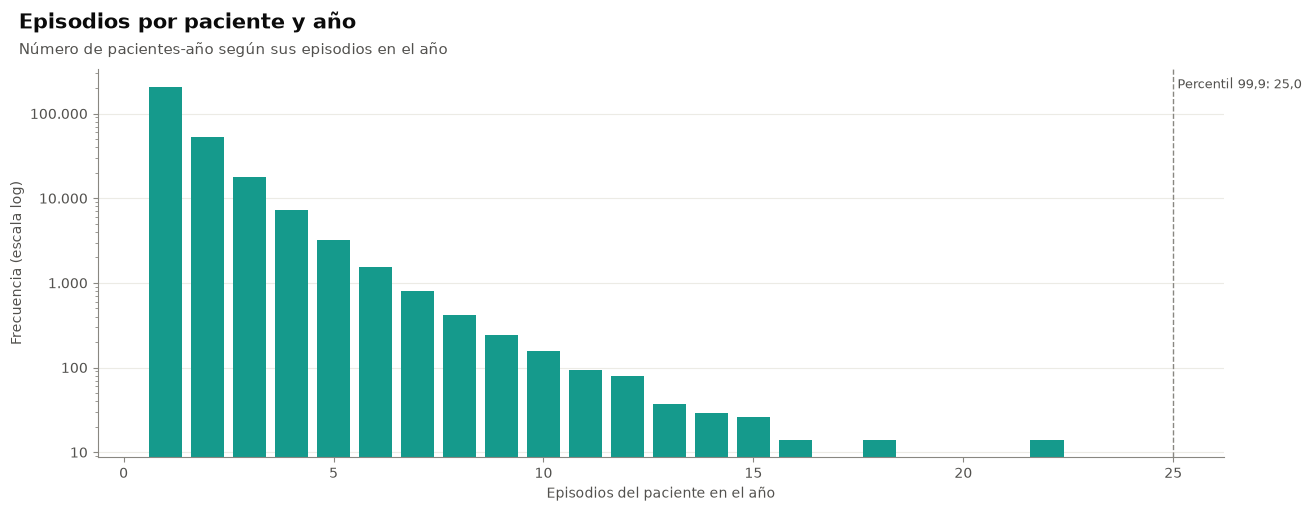

In [19]:
episodios_paciente_anio = conteo_por_paciente_anio(poblacion)
una_por_paciente_anio = ~pd.DataFrame({'p': poblacion['person_id'], 'a': poblacion['llegada'].dt.year}).duplicated()
grafico_conteos(episodios_paciente_anio[una_por_paciente_anio].value_counts(), limites_usados['paciente_muchos_episodios'],
                'Episodios por paciente y año', 'Número de pacientes-año según sus episodios en el año',
                '05_episodios_por_paciente_anio', 'Episodios del paciente en el año')

## 11. Edad en NaN
### Detección

Episodios con `edad` sin dato (sin `year_of_birth`), según el notebook 03.

### Episodios afectados

In [20]:
mostrar_afectados('edad_nan')

**Edad en NaN: episodios afectados**

,n,n_afectados,pct_afectados
marca,,,
edad_nan,442.598,<10,suprimido


**Edad en NaN: episodios afectados por grupo**

,n,n_edad_nan
grupo,,
1_contacto_breve,216.019,0
2_atencion_urgencias,192.046,0
3_hospitalizado,34.533,0


### Distribución

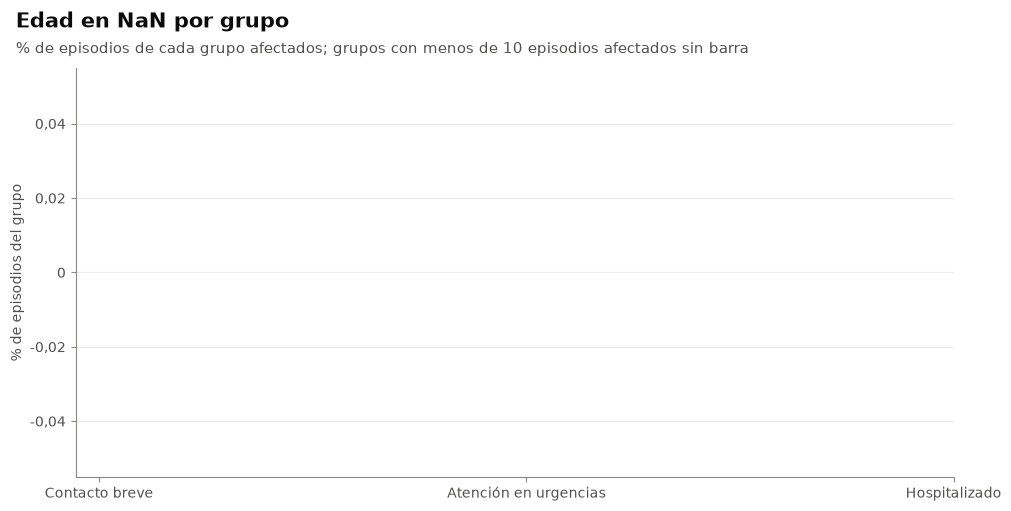

In [21]:
grafico_por_grupo('edad_nan', '05_edad_nan')

## 12. Dataset final
### 12.1 Reglas de episodio

Reglas de `REGLAS_EPISODIO` y su acción.

In [22]:
estado_reglas = pd.DataFrame(
    [{'regla': clave, 'descripcion': regla['descripcion'], 'deteccion': regla['deteccion'], 'accion': regla['accion']}
     for clave, regla in config.REGLAS_EPISODIO.items()]
).set_index('regla')
mostrar_tabla(estado_reglas, 'REGLAS_EPISODIO (src/config.py)')

**REGLAS_EPISODIO (src/config.py)**

,descripcion,deteccion,accion
regla,,,
los_extremo,LOS extremo,"LOS por encima del percentil 99 o 99,9 de su grupo (atención en urgencias u hospitalizado)",conservar
fin_fraccion_segundo,Fines con fracción de segundo,alguna visita del episodio tiene un fin de etapa con fracción de segundo,conservar
muchas_visitas_en_episodio,Muchas visitas unidas en un episodio,"n_visitas por encima del percentil 99,9",conservar
los_recortado,LOS recortado a 0,hospitalizado con inicio_piso anterior a la llegada (LOS recortado a 0),conservar
hosp_etapas_urg_despues_de_piso,Hospitalizado con etapas de urgencias después de subir a piso,hospitalizado con fin_urg > inicio_piso,conservar
contacto_breve_por_visitas_unidas,Contacto breve por visitas unidas,contacto breve con LOS ≥ 5 min: visitas sin etapas unidas en un mismo episodio (el LOS va de la primera a la última llegada),conservar
hosp_sin_inicio_piso,Hospitalizado sin inicio de piso,hospitalizado con inicio_piso vacío,conservar
atencion_menos_5min,Atención en urgencias con LOS < 5 min,grupo de atención en urgencias con LOS menor a 5 minutos,conservar
fin_urg_antes_llegada,Fin de urgencias antes de la llegada,fin_urg < llegada,conservar


### 12.2 Aplicación de las reglas

Se aplican las reglas a todos los episodios construidos (también a los de fuera de la población, que sirven como siguiente episodio en las reconsultas) y se crea la columna `valido_para_tiempos`.

In [23]:
marcas_todos = marcas.reindex(episodios.index, fill_value=False)
episodios_final, reporte_episodio = aplicar_reglas_episodio(episodios, marcas_todos)
mostrar_tabla(tabla_segura(reporte_episodio, conservar_ceros=True), 'Episodios afectados por cada acción aplicada')
tabla_medidas({
    'episodios antes de aplicar las reglas': len(episodios),
    'episodios después de aplicar las reglas': len(episodios_final),
    'episodios con valido_para_tiempos = True': int(episodios_final['valido_para_tiempos'].sum()),
}, 'Dataset final')

**Episodios afectados por cada acción aplicada**

,accion,n_afectados
regla,,
los_extremo,conservar,0
fin_fraccion_segundo,conservar,0
muchas_visitas_en_episodio,conservar,0
los_recortado,conservar,0
hosp_etapas_urg_despues_de_piso,conservar,0
contacto_breve_por_visitas_unidas,conservar,0
hosp_sin_inicio_piso,conservar,0
atencion_menos_5min,conservar,0
fin_urg_antes_llegada,conservar,0


**Dataset final**

,medida,valor
0,episodios antes de aplicar las reglas,468.550
1,episodios después de aplicar las reglas,468.550
2,episodios con valido_para_tiempos = True,468.550


### 12.3 Flujo de registros

Conteos de cada paso, desde las visitas de urgencias en la base hasta los episodios válidos para tiempos, con el número y el motivo de los que salen.

In [24]:
reglas_registro = metadatos_preliminar.get('reglas_registro', {})
quitadas = {config.REGLAS_REGISTRO[c]['descripcion'] if c in config.REGLAS_REGISTRO else c: d.get('n_visitas_quitadas', 0)
            for c, d in reglas_registro.items() if str(d.get('accion')).startswith('excluir')}
n_visitas_base = int(metadatos_preliminar['n_visitas_antes_de_reglas'])
n_visitas_limpias = int(metadatos_preliminar['n_visitas_despues_de_reglas'])
poblacion_final = episodios_final[episodios_final['en_poblacion']]
pasos = [
    ('Visitas de urgencias en la base', n_visitas_base, None),
    ('Visitas tras las exclusiones del notebook 03', n_visitas_limpias,
     'exclusiones: ' + '; '.join(f'{nombre} ({fmt_entero(n)})' for nombre, n in quitadas.items())),
    ('Episodios tras la fusión de visitas', len(episodios_final),
     f'visitas unidas en un mismo episodio (fusión de {config.UMBRAL_FUSION_MIN} min)'),
    ('Episodios en la población de análisis', len(poblacion_final),
     f'llegada fuera de {config.FECHA_INICIO_ANALISIS:%d/%m/%Y} – {config.FECHA_CORTE_ANALISIS:%d/%m/%Y}'),
    ('Episodios válidos para tiempos', int(poblacion_final['valido_para_tiempos'].sum()),
     'reglas de episodio con acción excluir_de_tiempos'),
]
flujo = pd.DataFrame(
    [{'paso': paso, 'n': n, 'n_salen': (pasos[i - 1][1] - n) if i else 0, 'motivo': motivo or '—'}
     for i, (paso, n, motivo) in enumerate(pasos)]
).set_index('paso')
mostrar_tabla(tabla_segura(flujo, conservar_ceros=True), 'Flujo de registros')

**Flujo de registros**

,n,n_salen,motivo
paso,,,
Visitas de urgencias en la base,598.088,0,—
Visitas tras las exclusiones del notebook 03,595.375,2.713,exclusiones: Año de nacimiento imposible (21); Edad negativa (1); Hospitalización que empieza antes de la llegada (2); Recorridos idénticos entre pacientes distintos (2.689)
Episodios tras la fusión de visitas,468.550,126.825,visitas unidas en un mismo episodio (fusión de 60 min)
Episodios en la población de análisis,442.598,25.952,llegada fuera de 01/01/2023 – 31/03/2026
Episodios válidos para tiempos,442.598,0,reglas de episodio con acción excluir_de_tiempos


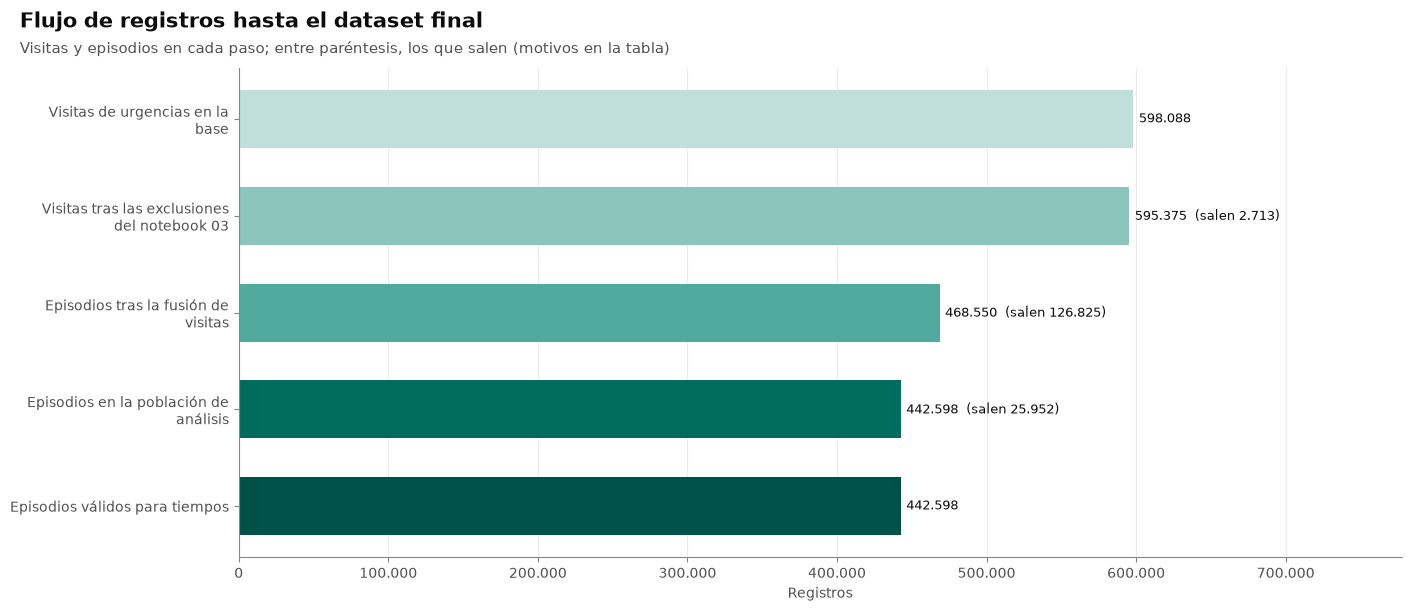

In [25]:
fig, ax = plt.subplots(figsize=(14, 6))
y = np.arange(len(flujo))[::-1]
colores = estilo.tonos('general', len(flujo))
ax.barh(y, flujo['n'], height=0.6, color=colores)
for yi, (paso, fila) in zip(y, flujo.iterrows()):
    texto = fmt_entero(fila['n'])
    if fila['n_salen'] > 0:
        salen = fmt_entero(fila['n_salen']) if fila['n_salen'] >= config.MIN_CELDA else f'<{config.MIN_CELDA}'
        texto += f'  (salen {salen})'
    ax.annotate(texto, xy=(fila['n'], yi), xytext=(4, 0), textcoords='offset points', va='center',
                fontsize=estilo.TAMANO_MINIMO, color=estilo.TEXTO)
ax.set_yticks(y, [envolver_etiqueta(p, 30) for p in flujo.index])
ax.set_xlim(0, flujo['n'].max() * 1.3)
ax.grid(False)
ax.grid(axis='x')
ax.set_xlabel('Registros')
titulo_hallazgo(fig, 'Flujo de registros hasta el dataset final',
                'Visitas y episodios en cada paso; entre paréntesis, los que salen (motivos en la tabla)')
guardar_figura(fig, '05_flujo_registros')
plt.show()

### 12.4 Exportación

Se guardan `data/interim/episodios_final.parquet` (con identificadores internos; solo en `data/interim/`, ignorado por git) y su `.json` de metadatos. Las columnas se describen en `docs/diccionario_episodios.md`.

In [26]:
episodios_final.to_parquet(config.DATA_INTERIM / 'episodios_final.parquet', index=False)

metadatos = {
    'dataset': 'final',
    'fecha_ejecucion': datetime.now().isoformat(timespec='seconds'),
    'origen': f'data/interim/{nombre_preliminar}.parquet',
    'umbral_fusion_min': config.UMBRAL_FUSION_MIN,
    'fecha_inicio_analisis': str(config.FECHA_INICIO_ANALISIS),
    'fecha_corte_analisis': str(config.FECHA_CORTE_ANALISIS),
    'sha256_sql': metadatos_preliminar.get('sha256_sql'),
    'reglas_registro': reglas_registro,
    'reglas_episodio': {
        clave: {'accion': regla['accion'], 'n_afectados': int(reporte_episodio.loc[clave, 'n_afectados'])}
        for clave, regla in config.REGLAS_EPISODIO.items()
    },
    'flujo': [{'paso': paso, 'n': int(fila['n']), 'n_salen': int(fila['n_salen']), 'motivo': fila['motivo']}
              for paso, fila in flujo.iterrows()],
    'n_filas': int(len(episodios_final)),
    'n_filas_en_poblacion': int(episodios_final['en_poblacion'].sum()),
    'n_filas_por_grupo_en_poblacion': {g: int(n) for g, n in poblacion_final['grupo'].value_counts().items()},
}
with open(config.DATA_INTERIM / 'episodios_final.json', 'w', encoding='utf-8') as archivo:
    json.dump(metadatos, archivo, ensure_ascii=False, indent=2)
tabla_medidas({'parquet': 'data/interim/episodios_final.parquet', 'metadatos': 'data/interim/episodios_final.json',
               'filas': len(episodios_final), 'columnas': episodios_final.shape[1]}, 'Archivos exportados')

**Archivos exportados**

,medida,valor
0,parquet,data/interim/episodios_final.parquet
1,metadatos,data/interim/episodios_final.json
2,filas,468.550
3,columnas,43
